En este vamos a realizar el EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PATH_FILE = "../../data/raw/Titanic.csv"

df = pd.read_csv(PATH_FILE)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Resumen de variables del dataset Titanic

| Variable | Definición | Key |
|---|---|---|
| `survival` | Supervivencia | 0 = No, 1 = Sí |
| `pclass` | Clase del pasajero, es decir, categoria de clase | 1 = 1ra, 2 = 2da, 3 = 3ra |
| `sex` | Sexo |  |
| `Age` | Edad en años |  |
| `sibsp` | Número de hermanos / cónyuges a bordo |  |
| `parch` | Número de padres / hijos a bordo |  |
| `ticket` | Número del billete |  |
| `fare` | Tarifa pagada por el pasajero |  |
| `cabin` | Número de cabina |  |
| `embarked` | Puerto de embarque | C = Cherbourg, Q = Queenstown, S = Southampton |

### Descripción breve
- `survival`: indica si el pasajero sobrevivió.
- `pclass`: clase del pasajero.
- `sex`: género del pasajero.
- `Age`: edad en años.
- `sibsp`: cantidad de hermanos o cónyuges a bordo.
- `parch`: cantidad de padres o hijos a bordo.
- `ticket`: identificador del boleto.
- `fare`: costo del pasaje.
- `cabin`: cabina asignada.
- `embarked`: puerto donde abordó.

In [3]:
# Se observa que hay 891 filas y 12 columnas, algunas de las cuales contienen valores nulos (age, cabin, embarked).
# Los tips de datos son variados, incluyendo enteros (int64), flotantes (float64) y strings (str) (cadenas de texto).
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
# Se observa que solo existen 3 columnas con valores nulos, siendo la columna cabin la que tiene más valores nulos (687), seguida de age (177) y embarked (2).
display(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
# Se observa que la edad promedio esta de los pasajeros es de 29.7 años, la mediana es de 28 años. La edad mínima es de 0.42 años y la máxima es de 80 años.
# Se observa que la media de hermanos y esposas a bordo es de 0.52, la mínima es de 0 y la máxima es de 8. Lo que nos indica que la mayoría de los pasajeros viajaban solos o con un acompañante.
# Se observa que la media de padres e hijos a bordo es de 0.38, la mínima es de 0 y la máxima es de 6. Lo que nos indica que la mayoría de los pasajeros viajaban solos o con un acompañante.
# Se observa que la media de la tarifa pagada es de 32.2, la mínima es de 0 y la máxima es de 512. Lo que nos indica que la mayoría de los pasajeros pagaron tarifas bajas. Esto podria indicar que la mayoria viajaba en tercera clase. La mediana es de 14.4, lo que nos indica que la media esta sesgada por unos pocos pasajeros que pagaron tarifas muy altas.

display(df.describe(include='all'))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


np.int64(891)

Survived
0    549
1    342
Name: count, dtype: int64

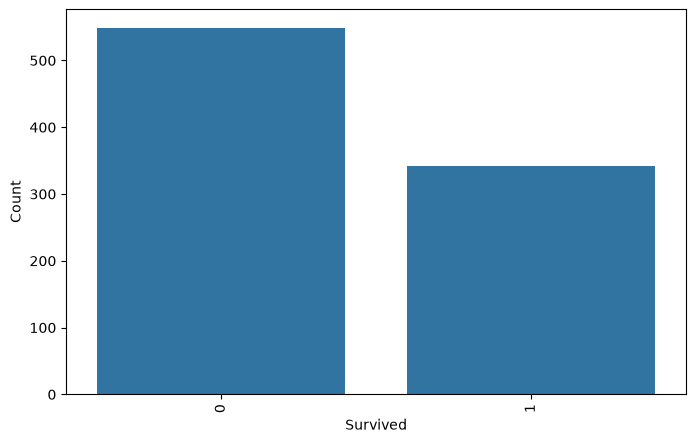

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

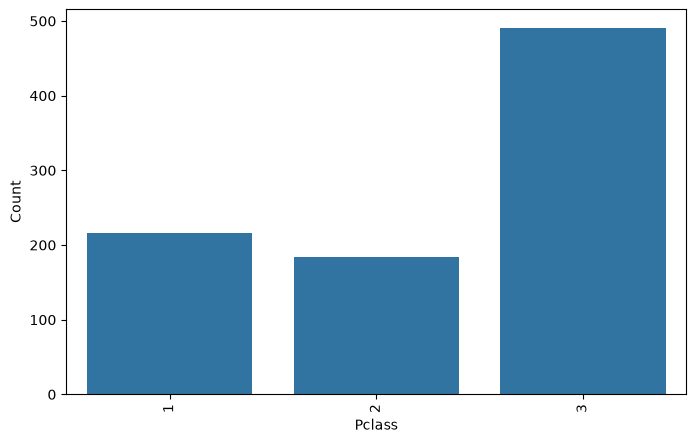

Sex
male      577
female    314
Name: count, dtype: int64

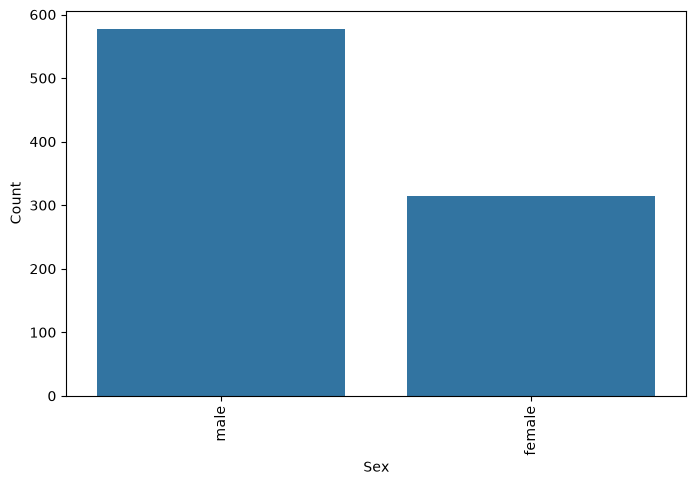

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

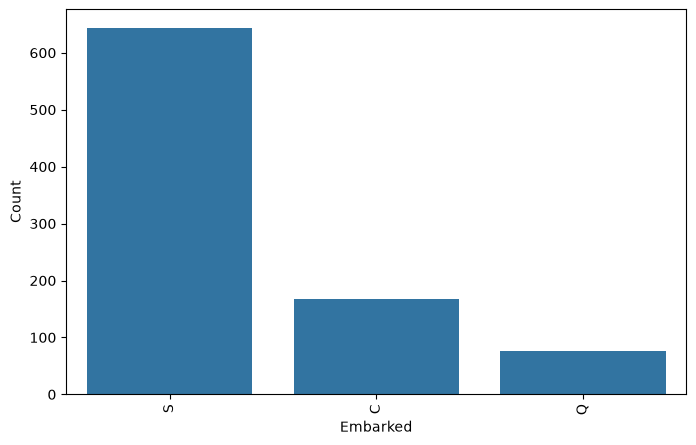

In [ ]:
display(df["PassengerId"].value_counts().sum())

columns_categorical = ["Survived", "Pclass", "Sex", "Embarked"]
for column in df.columns:
    if column in columns_categorical:
        value_counts = df[column].value_counts()

        display(value_counts)

        plt.figure(figsize=(8, 5))
        sns.barplot(x=value_counts.index, y=value_counts.values)
        plt.xticks(rotation=90)
        plt.ylabel('Count')
        plt.show()


# Survived (Target variable): 0 = No, 1 = Yes
# Se observa que la mayoría de los pasajeros no sobrevivieron (549) frente a los que sí sobrevivieron (342).

# Pclass: 1 = 1st, 2 = 2nd, 3 = 3rd
# Se observa que la mayoría de los pasajeros viajaban en tercera clase (491), seguida de segunda clase (184) y primera clase (216).

# Sex: male = hombre, female = mujer
# Se observa que la mayoría de los pasajeros eran hombres (577) frente a las mujeres (314).

# Embarked: C = Cherbourg, Q = Queenstown, S = Southampton
# Se observa que la mayoría de los pasajeros embarcaron en Southampton (644), seguida de Cherbourg (168) y Queenstown (77).

In [13]:
display(df.duplicated().sum())

np.int64(0)

Numerical features: ['Age', 'SibSp', 'Parch', 'Fare']


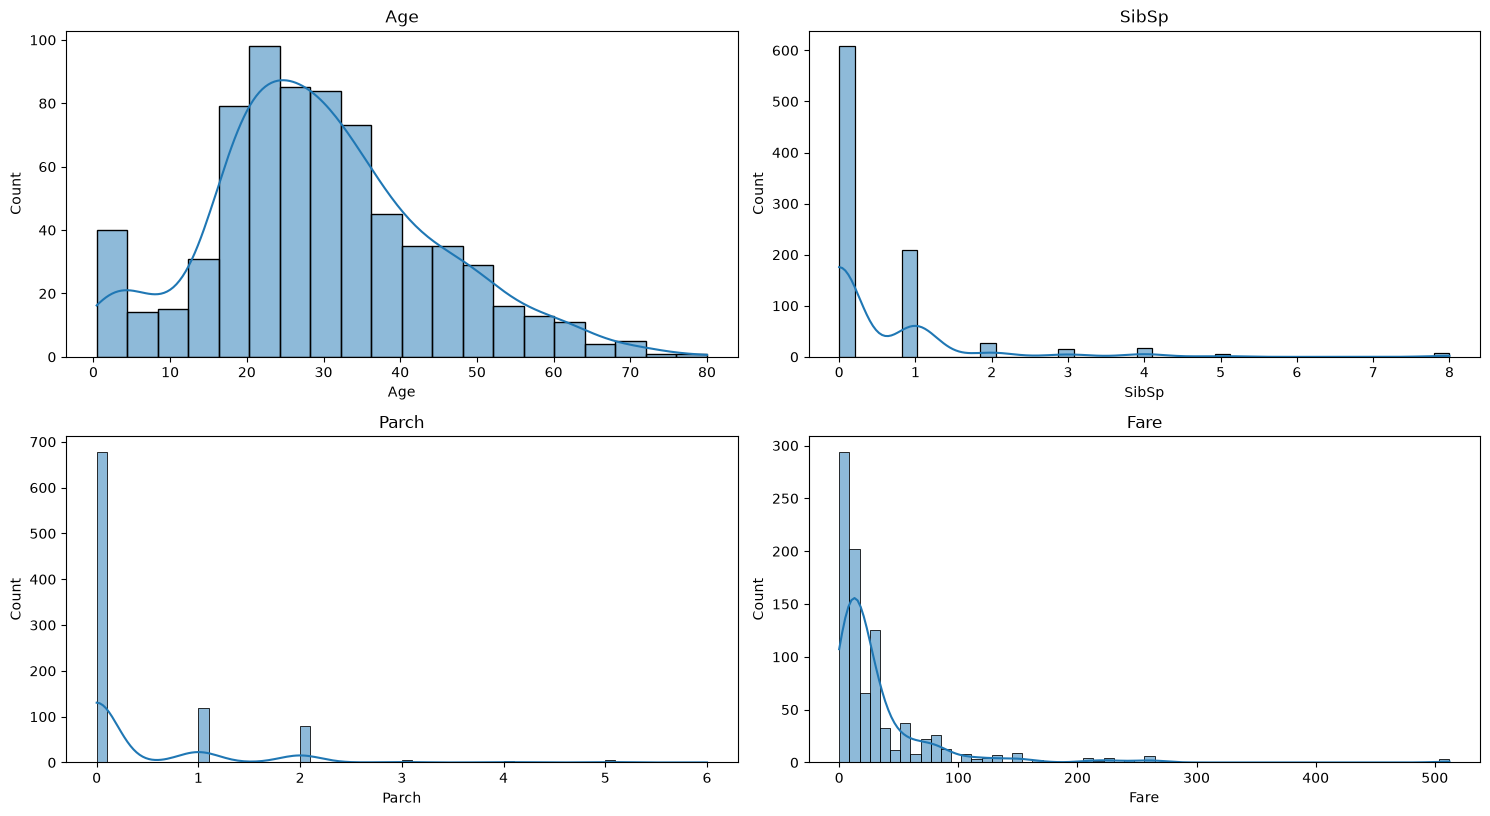

In [ ]:
#Plot the features
plt.figure(figsize=(15, 20))

numericas = df.select_dtypes(include=[np.number]).columns.tolist()

numericas.remove("PassengerId")  # Remove PassengerId from the list of numerical features
numericas.remove("Survived")  # Remove Survived from the list of numerical features
numericas.remove("Pclass")  # Remove Pclass from the list of numerical features

print("Numerical features:", numericas)

# Enumerate to get both feature name and index
for index, feature in enumerate(numericas, start=1):
    plt.subplot(5, 2, index)
    sns.histplot(x=feature, data=df, kde=True)
    plt.title(feature)

plt.tight_layout()
plt.show()

# Se observa que la mayoría de los pasajeros tienen edades entre 20 y 40 años, con un pico alrededor de los 25 años (entre 20 y 30). Hay algunos pasajeros muy jóvenes (menos de 5 años) y algunos muy mayores (más de 70 años).
# Se observa que la mayoría de los pasajeros tienen 0 hermanos/esposas a bordo, con un pico alrededor de 0. Hay algunos pasajeros con 1 o 2 hermanos/esposas a bordo, y muy pocos con más de 3.
# Se observa que la mayoría de los pasajeros tienen 0 padres/hijos a bordo, con un pico alrededor de 0. Hay algunos pasajeros con 1 o 2 padres/hijos a bordo, y muy pocos con más de 3.
# Se observa que la mayoría de los pasajeros pagaron tarifas bajas (menos de 100), con un pico alrededor de 10-20.

Límite Inferior de Tukey: -26.7240
Límite Superior de Tukey: 65.6344

Cantidad total de outliers detectados: 116
Porcentaje de outliers en la muestra: 13.02%

Registros identificados como atípicos:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.5500,NaN,S
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,NaN,1,0,17453,89.1042,C92,C
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S


/var/folders/l9/95mbz8cd0n16y967ljgd28sr0000gn/T/ipykernel_34158/3676925673.py:24: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['Fare'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))


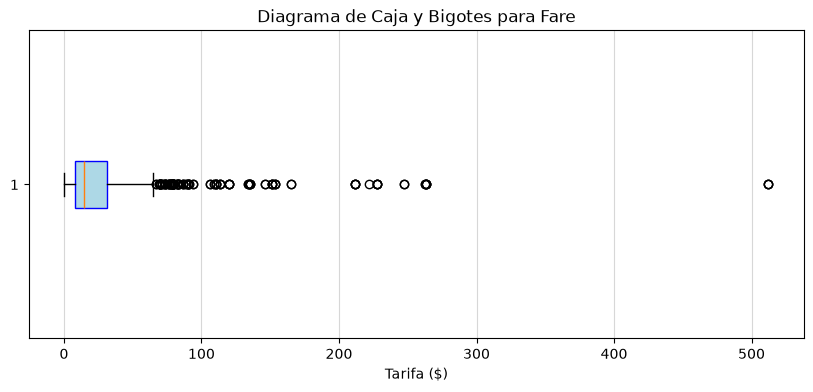

In [26]:
fare = df['Fare']
q1 = fare.quantile(0.25)
q3 = fare.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Límite Inferior de Tukey: {limite_inferior:.4f}")
print(f"Límite Superior de Tukey: {limite_superior:.4f}")

outliers_df = df[(fare < limite_inferior) | (fare > limite_superior)]
total_outliers = len(outliers_df)
porcentaje_outliers = (total_outliers / len(df)) * 100

print(f"\nCantidad total de outliers detectados: {total_outliers}")
print(f"Porcentaje de outliers en la muestra: {porcentaje_outliers:.2f}%")

print("\nRegistros identificados como atípicos:")
display(outliers_df)


plt.figure(figsize=(10, 4))
plt.boxplot(df['Fare'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))
plt.title('Diagrama de Caja y Bigotes para Fare')
plt.xlabel('Tarifa ($)')
plt.grid(axis='x', alpha=0.5)
plt.show()

# Se observa que la mayoría de los pasajeros pagaron tarifas bajas (menos de 100), con algunos pasajeros que pagaron tarifas muy altas (más de 200). Esto podría indicar que la mayoría viajaba en tercera clase, mientras que unos pocos viajaban en primera class, hay valores atípicos que podrían ser pasajeros de primera class o de lujo, y los valores se observan encima de los 70 dólares.

In [27]:
# Matrix de correlación
matriz_corr = df.corr(numeric_only=True)
display(matriz_corr)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


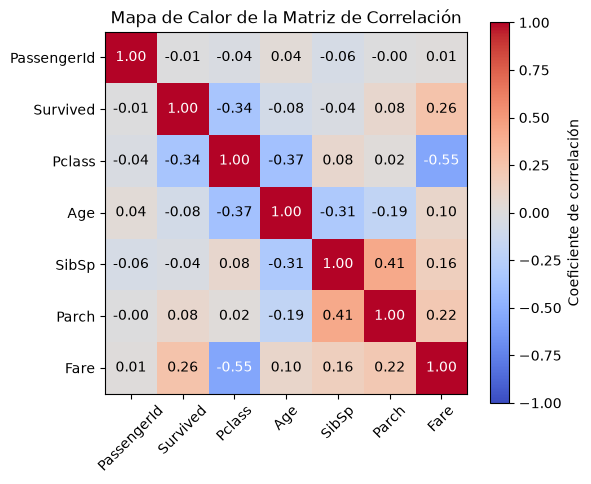

In [ ]:
plt.figure(figsize=(6, 5))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de correlación')

# Añadir etiquetas y valores
columnas = matriz_corr.columns
plt.xticks(range(len(columnas)), columnas, rotation=45)
plt.yticks(range(len(columnas)), columnas)

for i in range(len(columnas)):
    for j in range(len(columnas)):
        plt.text(j, i, f"{matriz_corr.iloc[i, j]:.2f}",
                 ha="center", va="center",
                 color="white" if abs(matriz_corr.iloc[i, j]) > 0.5 else "black")

plt.title('Mapa de Calor de la Matriz de Correlación')
plt.tight_layout()
plt.show()

# Correlaciones mas altas observadas:
# Se observa que las variables Fare y Pclass tienen una correlación negativa moderada (-0.55).
# Se observa que las variables Parch y SibSp tienen una correlación positiva moderada (0.41).
# Se observa una correlacion negativa moderada entre Pclass y Age (-0.37).
# Se observa una correlcion negativa moderada entre P-Class y Survived (-0.34).

# Correlaciones mas bajas observadas:
# Se observa una correlación positiva nula entre Parch y PassengerId (-0.00).
# Se observa una correlación negativa casi nula entre Survived y PassengerId, al igual que Fare y PassengerId (-0.01).
# Se observa una correlación positiva casi nula entre Parch y Pclass (0.02).

# Se observa que las variables menos correlacionadas generalmente son las que se relacionan con PassengerId, lo cual es esperado ya que esta variable es un identificador único para cada pasajero y no debería tener relación con las demás variables del dataset.
# Se observa qye de las mas correlacionadas, la mas alta es la correlación negativa entre Fare y Pclass, sin embargo, no existen variables con riesgo de multicolinealidad, ya que ninguna de las correlaciones es mayor a 0.8 o menor a -0.8.
